In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA

os.makedirs('imagenes', exist_ok=True)

In [9]:
df = pd.read_csv("Interactivos20260924194310.csv", encoding='latin-1')

df_nacional = df[df['Gender'] == 'Total'].copy()
df_nacional['Anio'] = df_nacional['Time'].str[:4].astype(int)
df_nacional['Trimestre'] = df_nacional['Time'].str[5].astype(int)
mes = (df_nacional['Trimestre'] - 1) * 3 + 1
df_nacional['Fecha'] = pd.to_datetime(
    df_nacional['Anio'].astype(str) + '-' + mes.astype(str) + '-01'
)

df_nacional = (df_nacional
               .rename(columns={'DATA': 'Tasa_desocupacion'})
               .sort_values('Fecha')
               .reset_index(drop=True))

print(len(df_nacional))   # debe ser 85
df_nacional.head()

85


,Indicator,Time,Geographic area,Datatype,Gender,Tasa_desocupacion,Anio,Trimestre,Fecha
0,10.2. Unemployment rate,2005 1Q,National,Percentages,Total,3.8,2005,1,2005-01-01
1,10.2. Unemployment rate,2005 2Q,National,Percentages,Total,3.5,2005,2,2005-04-01
2,10.2. Unemployment rate,2005 3Q,National,Percentages,Total,3.8,2005,3,2005-07-01
3,10.2. Unemployment rate,2005 4Q,National,Percentages,Total,3.1,2005,4,2005-10-01
4,10.2. Unemployment rate,2006 1Q,National,Percentages,Total,3.5,2006,1,2006-01-01


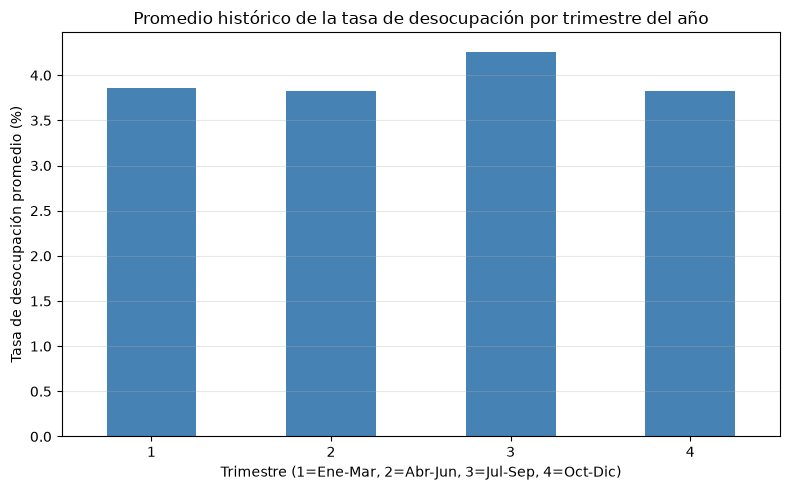

In [4]:
prom = df_nacional.groupby('Trimestre')['Tasa_desocupacion'].mean()

plt.figure(figsize=(8, 5))
prom.plot(kind='bar', color='steelblue')
plt.xticks(rotation=0)
plt.title('Promedio histórico de la tasa de desocupación por trimestre del año')
plt.xlabel('Trimestre (1=Ene-Mar, 2=Abr-Jun, 3=Jul-Sep, 4=Oct-Dic)')
plt.ylabel('Tasa de desocupación promedio (%)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('imagenes/estacionalidad_trimestre.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
n_test = 8
train = df_nacional.iloc[:-n_test]
test = df_nacional.iloc[-n_test:]
y_train = train['Tasa_desocupacion'].values
y_test = test['Tasa_desocupacion'].values

# Regresión lineal sobre el índice de tiempo
X = np.arange(len(df_nacional)).reshape(-1, 1)
lr = LinearRegression().fit(X[:-n_test], y_train)
pred_lr = lr.predict(X[-n_test:])

# ARIMA(2,1,2)
modelo = ARIMA(y_train, order=(2, 1, 2)).fit()
pred_arima = modelo.forecast(steps=n_test)

def metricas(real, pred):
    return mean_absolute_error(real, pred), np.sqrt(mean_squared_error(real, pred))

mae_lr, rmse_lr = metricas(y_test, pred_lr)
mae_ar, rmse_ar = metricas(y_test, pred_arima)

print(f"Regresión lineal -> MAE {mae_lr:.3f} | RMSE {rmse_lr:.3f}")
print(f"ARIMA(2,1,2)     -> MAE {mae_ar:.3f} | RMSE {rmse_ar:.3f}")

Regresión lineal -> MAE 0.755 | RMSE 0.772
ARIMA(2,1,2)     -> MAE 0.137 | RMSE 0.162


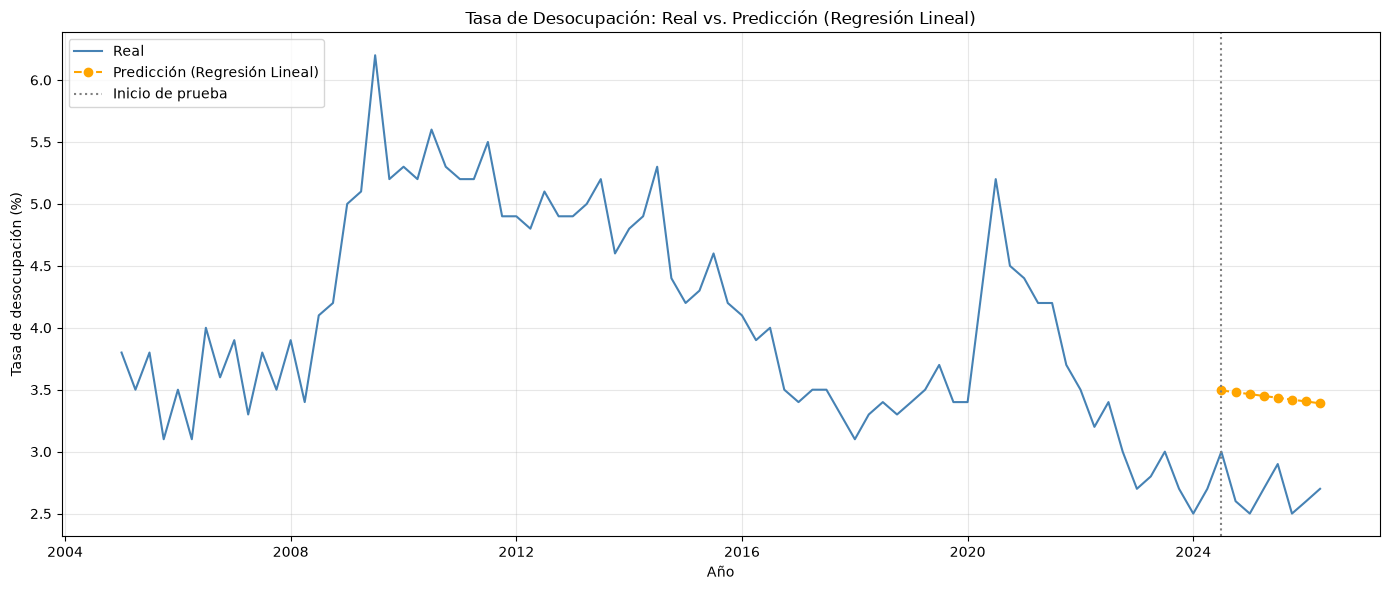

In [11]:
plt.figure(figsize=(14, 6))
plt.plot(df_nacional['Fecha'], df_nacional['Tasa_desocupacion'], color='steelblue', label='Real')
plt.plot(test['Fecha'], pred_lr, color='orange', marker='o', linestyle='--', label='Predicción (Regresión Lineal)')
plt.axvline(test['Fecha'].iloc[0], color='gray', linestyle=':', label='Inicio de prueba')
plt.title('Tasa de Desocupación: Real vs. Predicción (Regresión Lineal)')
plt.xlabel('Año')
plt.ylabel('Tasa de desocupación (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('imagenes/regresion_lineal.png', dpi=150, bbox_inches='tight')
plt.show()

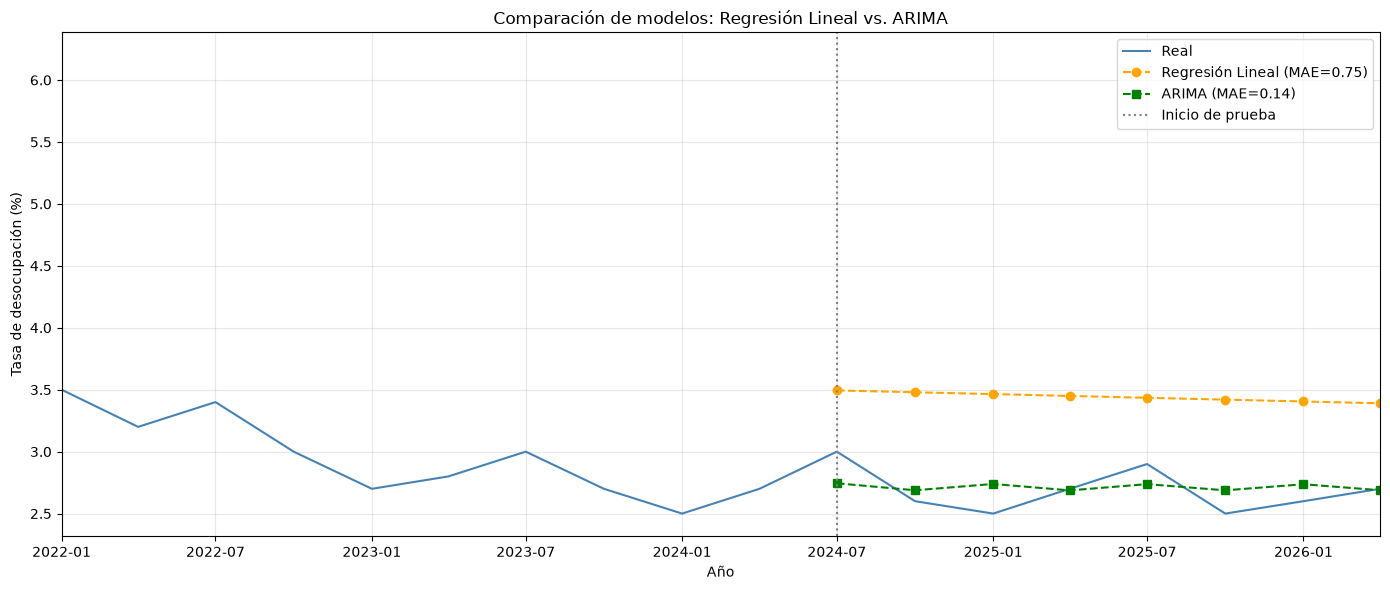

In [12]:
plt.figure(figsize=(14, 6))
plt.plot(df_nacional['Fecha'], df_nacional['Tasa_desocupacion'], color='steelblue', label='Real')
plt.plot(test['Fecha'], pred_lr, color='orange', marker='o', linestyle='--',
         label=f'Regresión Lineal (MAE={mae_lr:.2f})')
plt.plot(test['Fecha'], pred_arima, color='green', marker='s', linestyle='--',
         label=f'ARIMA (MAE={mae_ar:.2f})')
plt.axvline(test['Fecha'].iloc[0], color='gray', linestyle=':', label='Inicio de prueba')
plt.xlim(pd.Timestamp('2022-01-01'), df_nacional['Fecha'].iloc[-1])
plt.title('Comparación de modelos: Regresión Lineal vs. ARIMA')
plt.xlabel('Año')
plt.ylabel('Tasa de desocupación (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('imagenes/comparacion_modelos.png', dpi=150, bbox_inches='tight')
plt.show()

85 2026 2T
Trimestre  Prediccion  IC95_inf  IC95_sup
  2026 3T        2.76      2.07      3.46
  2026 4T        2.68      1.80      3.56
  2027 1T        2.76      1.70      3.81
  2027 2T        2.68      1.50      3.85


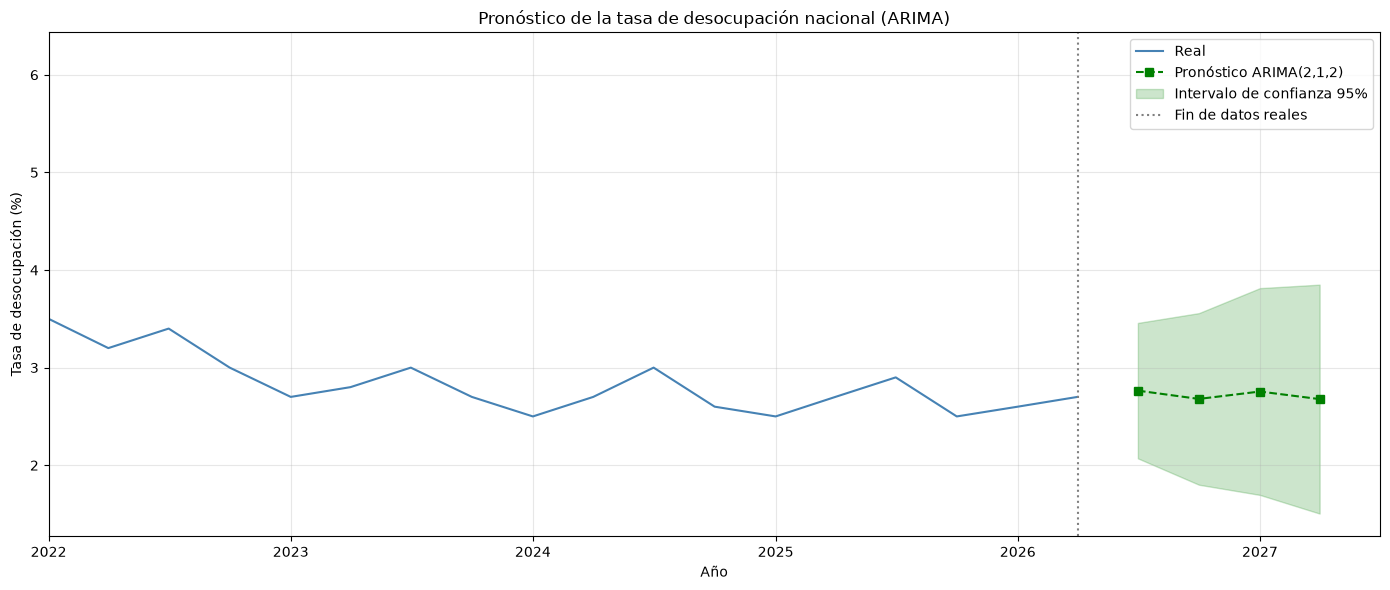

In [13]:
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

df = pd.read_csv("Interactivos20260924194310.csv", encoding='latin-1')
d = df[df['Gender']=='Total'].copy()
d['Anio']=d['Time'].str[:4].astype(int); d['Trimestre']=d['Time'].str[5].astype(int)
d['Fecha']=pd.to_datetime(d['Anio'].astype(str)+'-'+((d['Trimestre']-1)*3+1).astype(str)+'-01')
d=d.rename(columns={'DATA':'Tasa_desocupacion'}).sort_values('Fecha').reset_index(drop=True)
y=d['Tasa_desocupacion'].values
print(len(d), d['Time'].iloc[-1])

# Etapa 7: reentrenar con TODA la serie y pronosticar 4 trimestres
n_futuro=4
res=ARIMA(y, order=(2,1,2)).fit()
fc=res.get_forecast(steps=n_futuro)
media=fc.predicted_mean
ic=fc.conf_int(alpha=0.05)
fechas=pd.date_range(d['Fecha'].iloc[-1]+pd.DateOffset(months=3), periods=n_futuro, freq='QS')
etq=[f"{f.year} {(f.month-1)//3+1}T" for f in fechas]
pred=pd.DataFrame({'Trimestre':etq,'Prediccion':media.round(2),'IC95_inf':ic[:,0].round(2),'IC95_sup':ic[:,1].round(2)})
print(pred.to_string(index=False))

plt.figure(figsize=(14,6))
plt.plot(d['Fecha'],y,color='steelblue',label='Real')
plt.plot(fechas,media,color='green',marker='s',linestyle='--',label='Pronóstico ARIMA(2,1,2)')
plt.fill_between(fechas,ic[:,0],ic[:,1],color='green',alpha=0.2,label='Intervalo de confianza 95%')
plt.axvline(d['Fecha'].iloc[-1],color='gray',linestyle=':',label='Fin de datos reales')
plt.xlim(pd.Timestamp('2022-01-01'),fechas[-1]+pd.DateOffset(months=3))
plt.title('Pronóstico de la tasa de desocupación nacional (ARIMA)')
plt.xlabel('Año'); plt.ylabel('Tasa de desocupación (%)'); plt.legend(); plt.grid(True,alpha=0.3)
plt.tight_layout()
plt.savefig('imagenes/pronostico_futuro.png', dpi=150, bbox_inches='tight')
plt.show()

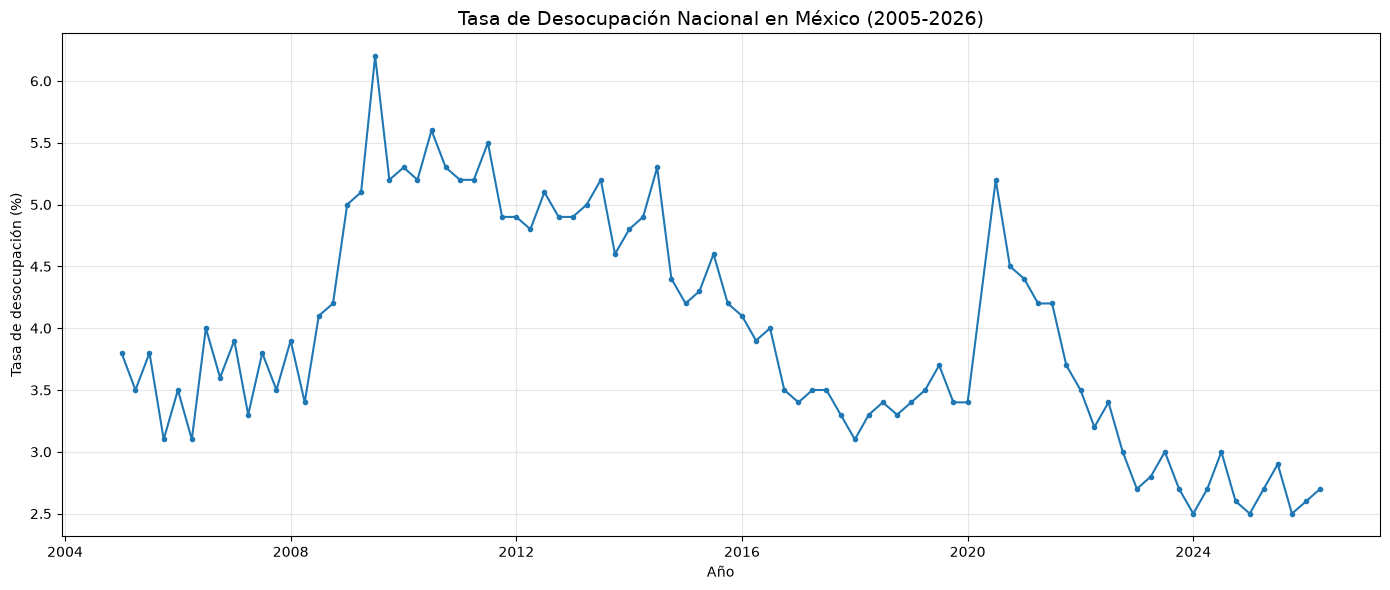

In [14]:
plt.figure(figsize=(14, 6))
plt.plot(df_nacional['Fecha'], df_nacional['Tasa_desocupacion'], marker='o', markersize=3, linewidth=1.5)
plt.title('Tasa de Desocupación Nacional en México (2005-2026)', fontsize=14)
plt.xlabel('Año')
plt.ylabel('Tasa de desocupación (%)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('imagenes/serie_historica.png', dpi=150, bbox_inches='tight')
plt.show()